# LeetCode #727: Minimum Window Subsequence

https://leetcode.com/problems/minimum-window-subsequence/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force (Two Pointers from Every Position)** | $O(|S| \cdot |S| \cdot |T|)$ | $O(1)$ |
| **Optimal: DP ★** | $O(|S| \cdot |T|)$ | $O(|S| \cdot |T|)$ |

---

## Understanding the Methods

### Brute Force (Two Pointers from Every Position)
For every starting position in S, use two pointers to find the smallest window containing T as a subsequence. O(|S|^2 * |T|) in the worst case.

### Optimal: DP ★
Define dp[i][j] as the starting index in S such that S[dp[i][j]..i] contains T[0..j] as a subsequence. Alternatively, use a forward-backward two-pointer approach: scan forward to find a window containing T, then scan backward to minimize it. Each character in S is processed a constant number of times per T character.

**Why this is better than Brute Force:** The DP/two-pass approach ensures each position is evaluated systematically, avoiding redundant scans and achieving O(|S| * |T|) time.

**Constraints:**
* 1 <= s.length <= 2 * 10^4
* 1 <= t.length <= 100
* s and t consist of lowercase English letters

## Solutions

### C#

In [ ]:
public class Solution {
    public string MinWindow(string s1, string s2) {
        int m = s1.Length, n = s2.Length;
        int bestStart = -1, bestLen = int.MaxValue;
        int i = 0;
        while (i < m) {
            // Forward pass: find window containing s2
            int j = 0;
            int start = i;
            while (start < m && j < n) {
                if (s1[start] == s2[j]) j++;
                start++;
            }
            if (j < n) break;
            // Backward pass: minimize window
            int end = start - 1;
            j = n - 1;
            while (j >= 0) {
                if (s1[end] == s2[j]) j--;
                end--;
            }
            end++;
            if (start - end < bestLen) {
                bestLen = start - end;
                bestStart = end;
            }
            i = end + 1;
        }
        return bestStart == -1 ? "" : s1.Substring(bestStart, bestLen);
    }
}

### Python

In [ ]:
class Solution:
    def minWindow(self, s1: str, s2: str) -> str:
        m, n = len(s1), len(s2)
        best = ""
        i = 0
        while i < m:
            # Forward: find s2 as subsequence starting from i
            j = 0
            k = i
            while k < m and j < n:
                if s1[k] == s2[j]:
                    j += 1
                k += 1
            if j < n:
                break
            # Backward: minimize the window
            end = k
            j = n - 1
            k -= 1
            while j >= 0:
                if s1[k] == s2[j]:
                    j -= 1
                k -= 1
            k += 1
            if not best or end - k < len(best):
                best = s1[k:end]
            i = k + 1
        return best

### Go

In [ ]:
func minWindow(s1 string, s2 string) string {
    m, n := len(s1), len(s2)
    best := ""
    i := 0
    for i < m {
        j, k := 0, i
        for k < m && j < n {
            if s1[k] == s2[j] { j++ }
            k++
        }
        if j < n { break }
        end := k
        j = n - 1
        k--
        for j >= 0 {
            if s1[k] == s2[j] { j-- }
            k--
        }
        k++
        if best == "" || end-k < len(best) {
            best = s1[k:end]
        }
        i = k + 1
    }
    return best
}

### Rust

In [ ]:
impl Solution {
    pub fn min_window(s1: String, s2: String) -> String {
        let s1 = s1.as_bytes();
        let s2 = s2.as_bytes();
        let (m, n) = (s1.len(), s2.len());
        let mut best_start = 0usize;
        let mut best_len = usize::MAX;
        let mut i = 0;
        while i < m {
            let mut j = 0;
            let mut k = i;
            while k < m && j < n {
                if s1[k] == s2[j] { j += 1; }
                k += 1;
            }
            if j < n { break; }
            let end = k;
            j = n;
            k -= 1;
            while j > 0 {
                if s1[k] == s2[j - 1] { j -= 1; }
                if j > 0 { k -= 1; }
            }
            if end - k < best_len {
                best_len = end - k;
                best_start = k;
            }
            i = k + 1;
        }
        if best_len == usize::MAX {
            String::new()
        } else {
            String::from_utf8(s1[best_start..best_start + best_len].to_vec()).unwrap()
        }
    }
}

## Example Scenarios

### 1. Common Case — Several Windows, Pick the Shortest
**Input:** `s1 = "abcdebdde", s2 = "bde"`

Scan forward from `i = 0`: `b` at 1, `d` at 3, `e` at 4 — so `s1[0..4]` already contains `"bde"`. Now walk *backward* from index 4 to tighten the left edge: `e` at 4, `d` at 3, `b` at 1, giving the window `s1[1..4] = "bcde"` (length 4). Restart from `i = 2`: the next window is `s1[5..8] = "bdde"` (also length 4) — not strictly shorter, so the first one wins. From `i = 6` there is no `b` left, so the loop breaks.

Both candidates have length 4, and ties keep the **leftmost** window. **Output:** `"bcde"`

### 2. Slightly Complex — Overlapping Starts, Duplicate Letters
**Input:** `s1 = "aabab", s2 = "ab"`

Forward from `i = 0` consumes `a` at 0 and `b` at 2; the backward pass slides the `a` forward to index 1, so the window is `s1[1..2] = "ab"` (length 2). Restarting at `i = 2` finds `s1[3..4] = "ab"`, also length 2. The duplicate leading `a` is exactly what the backward pass exists to discard — a pure forward scan would have reported `"aab"`.

**Output:** `"ab"` (length 2)

### 3. Edge Case: Time Factor — Every Restart Rescans a Long Run
**Input:** `s1 = "aaaaaaaaab", s2 = "aab"`

Nine `a`s then one `b`. The forward pass has to walk all 10 characters before `t` is complete, and the backward pass then rewinds to index 7, yielding `s1[7..9] = "aab"`. The next restart at `i = 8` runs off the end with `j < n` and breaks. This is the shape that makes the naive "restart at every index" version $O(|S|^2 \cdot |T|)$: each of the $|S|$ starts can rescan a long run. The two-pass/DP formulation caps the work at $O(|S| \cdot |T|)$.

**Output:** `"aab"` (length 3)

### 4. Edge Case: Space Factor — Window Is the Entire String
**Input:** `s1 = "abc", s2 = "abc"`

Every character of `s1` is needed, so the window cannot be tightened at all: forward ends at 3, backward returns to 0, and the answer is the whole input. The DP table is $|S| \times |T|$ — here $3 \times 3$ — which is the formulation's memory cost; the two-pointer version shown above answers the same question in $O(1)$ extra space, which matters at the constraint ceiling of $|S| = 2 \times 10^4$ and $|T| = 100$ (2 × 10⁶ DP cells).

**Output:** `"abc"` (length 3)

### 5. Almost-Impossible but Plausible — Right Letters, Wrong Order
**Input:** `s1 = "abcd", s2 = "dc"`

Both `d` and `c` appear in `s1`, so a frequency-based (Minimum Window *Substring*) check would happily report a match. But a **subsequence** must preserve order, and `d` only occurs *after* `c`. The forward pass finds `d` at index 3, then runs off the end still needing `c`, so `j < n` and the loop breaks immediately with no window ever recorded.

**Output:** `""`

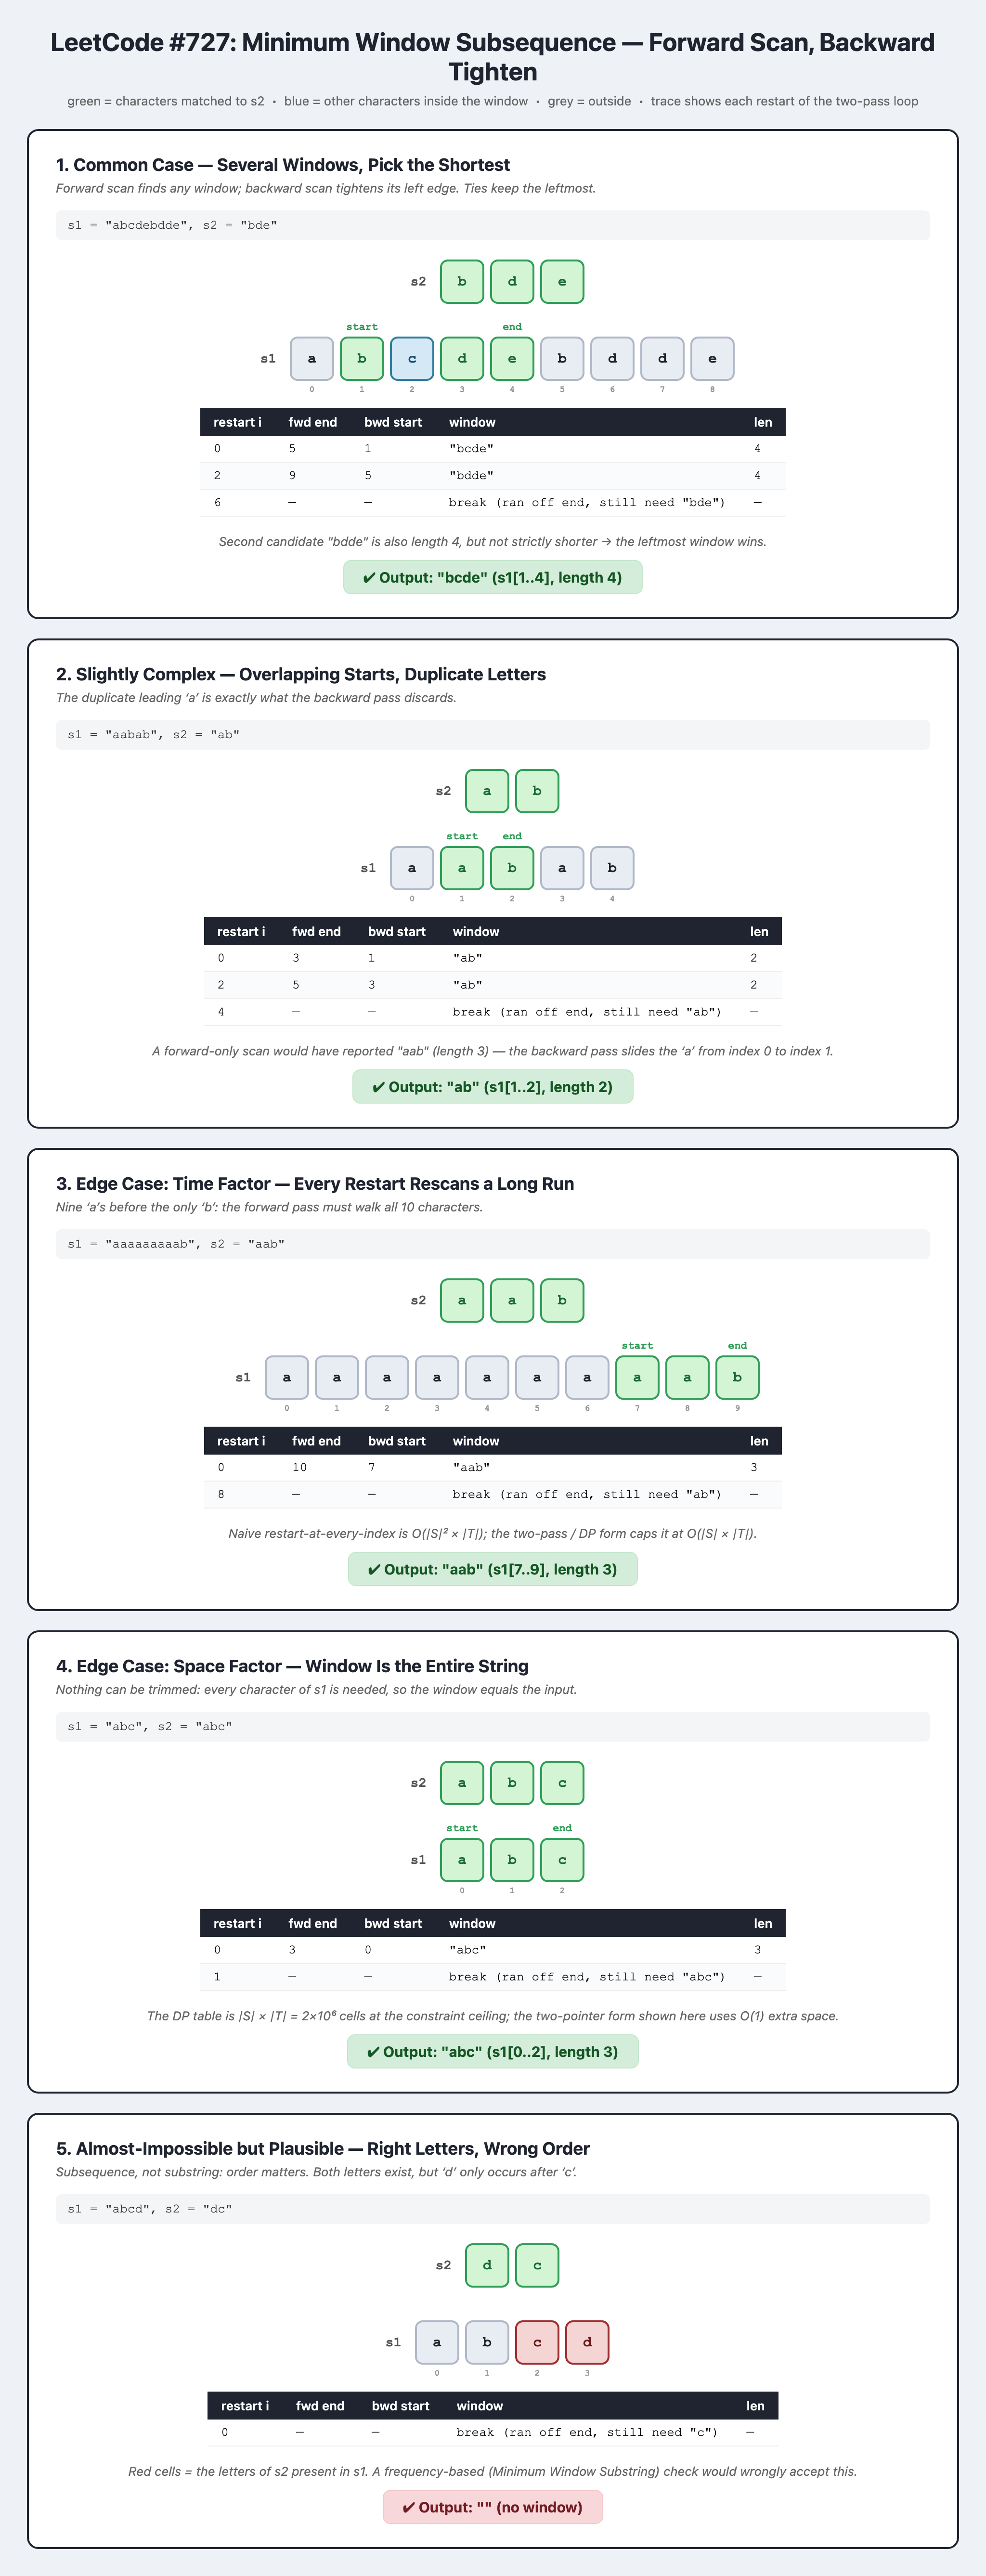